In [257]:
import httpx  # fetches things over the internet
import pandas as pd  # tables of data
import matplotlib.pyplot as plt  # charts

API_URL = "https://api.neso.energy/api/3/action/datastore_search"
RESOURCE_ID = "8a4a771c-3929-4e56-93ad-cdf13219dea5"

response = httpx.get(API_URL, params={"resource_id": RESOURCE_ID, "limit": 100000})
payload = response.json()  # the response, converted into a Python dictionary

payload.keys()

dict_keys(['help', 'success', 'result'])

In [258]:
records = payload["result"]["records"]
print(f"Fetched {len(records)} records")
records[0]

Fetched 11470 records


{'_id': 1,
 'SETTLEMENT_DATE': '2026-01-01',
 'SETTLEMENT_PERIOD': 1,
 'ND': 25107,
 'FORECAST_ACTUAL_INDICATOR': 'A',
 'TSD': 29668,
 'ENGLAND_WALES_DEMAND': 23625,
 'EMBEDDED_WIND_GENERATION': 4146,
 'EMBEDDED_WIND_CAPACITY': 6417,
 'EMBEDDED_SOLAR_GENERATION': 0,
 'EMBEDDED_SOLAR_CAPACITY': 22300,
 'NON_BM_STOR': 0,
 'PUMP_STORAGE_PUMPING': 455,
 'SCOTTISH_TRANSFER': 2945,
 'IFA_FLOW': -1143,
 'IFA2_FLOW': -610,
 'BRITNED_FLOW': 989,
 'MOYLE_FLOW': -361,
 'EAST_WEST_FLOW': -527,
 'NEMO_FLOW': 209,
 'NSL_FLOW': 677,
 'ELECLINK_FLOW': -352,
 'VIKING_FLOW': 1021,
 'GREENLINK_FLOW': -513}

In [259]:
df = pd.DataFrame(records)
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Shape: 11470 rows, 24 columns


,_id,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,FORECAST_ACTUAL_INDICATOR,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,...,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
0,1,2026-01-01,1,25107,A,29668,23625,4146,6417,0,...,-1143,-610,989,-361,-527,209,677,-352,1021,-513
1,2,2026-01-01,2,25881,A,30361,24341,4188,6417,0,...,-1132,-606,1005,-361,-453,243,648,-359,994,-514
2,3,2026-01-01,3,25355,A,30681,23805,4085,6417,0,...,-1433,-594,844,-361,-524,343,667,-754,994,-514
3,4,2026-01-01,4,24762,A,30225,23226,4092,6417,0,...,-1469,-589,837,-361,-531,346,650,-770,990,-514
4,5,2026-01-01,5,24111,A,29092,22653,4044,6417,0,...,-1236,-431,949,-361,-531,146,413,-475,990,-513


In [260]:
df.columns

Index(['_id', 'SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND',
       'FORECAST_ACTUAL_INDICATOR', 'TSD', 'ENGLAND_WALES_DEMAND',
       'EMBEDDED_WIND_GENERATION', 'EMBEDDED_WIND_CAPACITY',
       'EMBEDDED_SOLAR_GENERATION', 'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR',
       'PUMP_STORAGE_PUMPING', 'SCOTTISH_TRANSFER', 'IFA_FLOW', 'IFA2_FLOW',
       'BRITNED_FLOW', 'MOYLE_FLOW', 'EAST_WEST_FLOW', 'NEMO_FLOW', 'NSL_FLOW',
       'ELECLINK_FLOW', 'VIKING_FLOW', 'GREENLINK_FLOW'],
      dtype='str')

In [261]:
df.describe()

,_id,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,IFA_FLOW,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW
count,11470.000000,11470.000000,11470.000000,11470.000000,11470.000000,11470.000000,11470.0,11470.000000,11470.000000,11470.0,...,11470.000000,11470.000000,11470.000000,11470.000000,11470.000000,11470.000000,11470.000000,11470.000000,11470.000000,11470.000000
mean,5735.500000,24.495990,25514.652659,27926.433827,23398.703487,1845.630776,6417.0,2922.465998,23277.121622,0.0,...,1219.159634,719.363383,220.556234,-271.185004,-211.522232,280.148474,585.305841,788.734786,317.514473,-325.473758
std,3311.248128,13.851879,6059.207844,6329.252957,5606.550379,1241.014257,0.0,4145.824037,562.741979,0.0,...,563.967034,398.576150,744.825473,208.493921,236.063784,656.278899,974.923065,329.108988,907.748318,244.784786
min,1.000000,1.000000,12626.000000,13803.000000,11067.000000,145.000000,6417.0,0.000000,22300.000000,0.0,...,-1521.000000,-1027.000000,-1095.000000,-453.000000,-532.000000,-1043.000000,-1453.000000,-951.000000,-1454.000000,-538.000000
25%,2868.250000,12.250000,21287.250000,23485.000000,19500.250000,860.250000,6417.0,0.000000,22814.000000,0.0,...,1000.000000,528.250000,-438.000000,-451.000000,-511.000000,-191.750000,-5.000000,690.000000,-385.000000,-514.000000
50%,5735.500000,24.000000,24408.000000,26913.000000,22416.500000,1484.000000,6417.0,250.500000,23468.000000,0.0,...,1500.000000,972.000000,375.000000,-362.000000,-120.000000,442.500000,1037.000000,995.000000,403.000000,-496.000000
75%,8602.750000,36.000000,28447.000000,31033.000000,26127.000000,2546.750000,6417.0,5127.500000,23798.000000,0.0,...,1507.000000,992.000000,996.000000,-46.000000,0.000000,884.000000,1397.000000,997.000000,1138.000000,-79.000000
max,11470.000000,48.000000,47382.000000,50101.000000,42669.000000,5761.000000,6417.0,16393.000000,23963.000000,0.0,...,2012.000000,994.000000,1079.000000,295.000000,274.000000,1017.000000,1443.000000,1000.000000,1432.000000,300.000000


In [262]:
df["SETTLEMENT_DATE"].min(), df["SETTLEMENT_DATE"].max()

('2026-01-01', '2026-08-27')

Plotting a chart of england wales demand by date

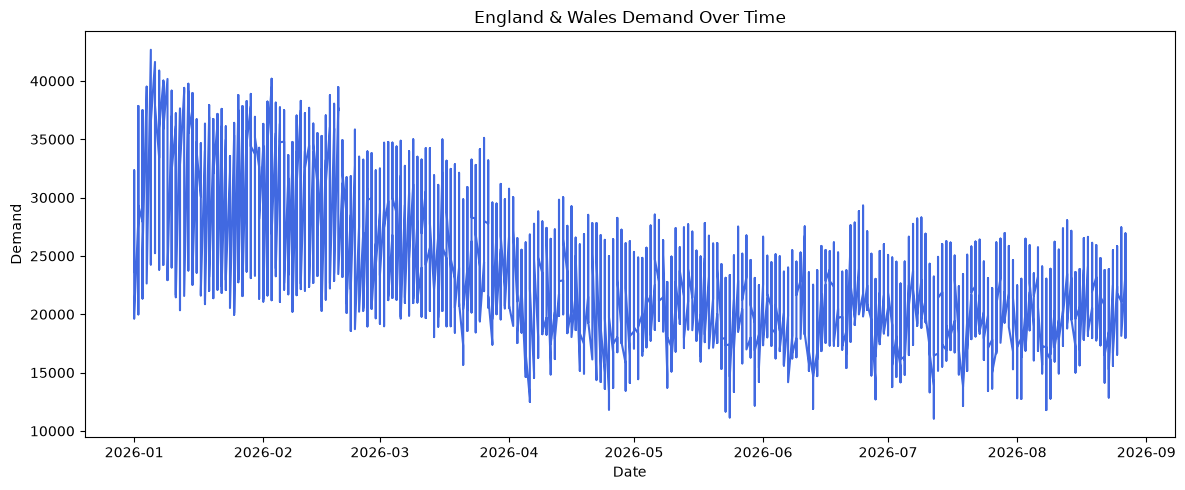

In [263]:
# make sure the date is treated as a real date
df["SETTLEMENT_DATE"] = pd.to_datetime(df["SETTLEMENT_DATE"])

# make sure demand is numeric
df["ENGLAND_WALES_DEMAND"] = pd.to_numeric(df["ENGLAND_WALES_DEMAND"], errors="coerce")

# sort so the line runs chronologically
df = df.sort_values("SETTLEMENT_DATE")

plt.figure(figsize=(12, 5))
plt.plot(df["SETTLEMENT_DATE"], df["ENGLAND_WALES_DEMAND"], color="royalblue")
plt.title("England & Wales Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.tight_layout()


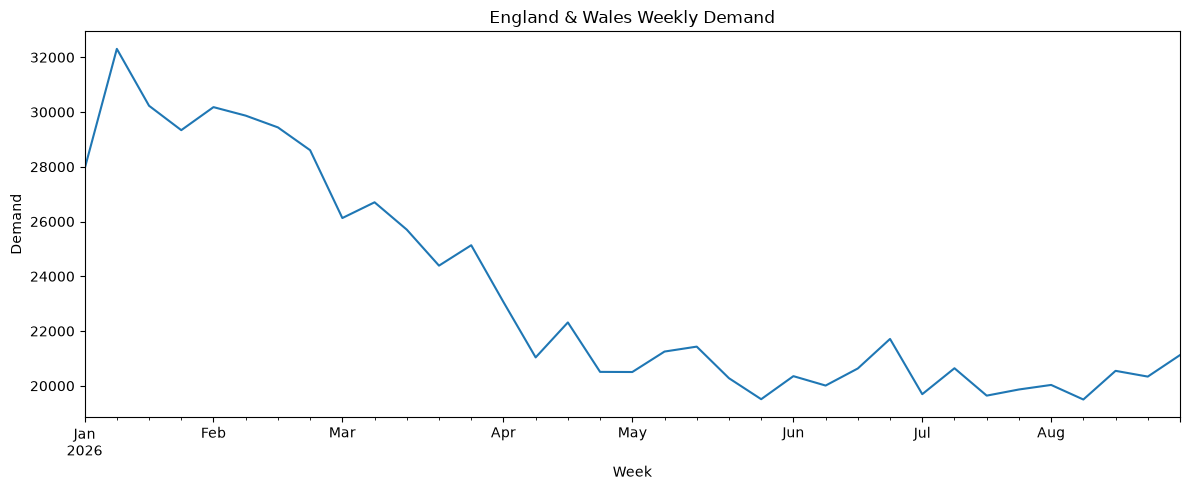

In [264]:
df["SETTLEMENT_DATE"] = pd.to_datetime(df["SETTLEMENT_DATE"])
df["ENGLAND_WALES_DEMAND"] = pd.to_numeric(df["ENGLAND_WALES_DEMAND"], errors="coerce")

df = df.sort_values("SETTLEMENT_DATE").set_index("SETTLEMENT_DATE")

# weekly average demand
weekly_demand = df["ENGLAND_WALES_DEMAND"].resample("W").mean()

# if you want total demand for each week instead, use .sum() instead of .mean()
# weekly_demand = df["ENGLAND_WALES_DEMAND"].resample("W").sum()

weekly_demand.plot(figsize=(12, 5), title="England & Wales Weekly Demand")
plt.xlabel("Week")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()